# 24 — Rare-event Monte Carlo: the Gaussian-noise tail of the bank statistic down to FAP 10⁻⁹

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 51. In ideal Gaussian noise the false-alarm probability of the bank statistic λ = max ρ² (160 templates × all lags) is estimated by **subset simulation** (multilevel splitting with preconditioned Crank–Nicolson Markov moves, which leave the Gaussian noise law invariant) down to 10⁻⁹, where plain Monte Carlo would need 10¹¹ windows. The result is compared with (i) plain Monte Carlo where it is feasible, (ii) the analytic formula FAP = 1 − (1 − e^{−λ/2})^{N_eff} with the N_eff of notebook 03, and (iii) what the real noise gives (the empirical thresholds of notebook 12).

**What it does not do.** It is the *Gaussian* null; the real-noise tail is dominated by glitches and cannot be obtained this way. The subset-simulation error is estimated from independent repetitions, not from a single run, and the chains are correlated within a level.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gwosc_tools as g
g.style()
S1 = g.load_chunk(3)["S1"]; BANK = g.SGBank(S1)
def stat(X): return BANK.scan(X)["rho2"]
def noise(n, rng): return (rng.normal(size=(n, g.NB)) + 1j * rng.normal(size=(n, g.NB))) * g.BAND
N_EFF = g.load_json("03_summary.json")["N_eff"]; print("N_eff =", round(N_EFF))
rng = np.random.default_rng(24)
t0_ = time.time(); X = noise(20000, rng); direct = stat(X); print("plain Monte Carlo of 20000 windows: %.0f s" % (time.time() - t0_))

N_eff = 6794


plain Monte Carlo of 20000 windows: 56 s


In [2]:
def subset_simulation(seed, n=2000, p0=0.1, levels=12, beta=0.6, target_p=1e-9):
    r = np.random.default_rng(seed); X = noise(n, r); lam = stat(X); p = 1.0; thr = []; probs = []
    for lv in range(levels):
        t = np.quantile(lam, 1 - p0); thr.append(t); probs.append(p0); p *= p0
        if p < target_p * 0.5: break
        seeds = np.where(lam > t)[0]; ns = len(seeds); per = int(np.ceil(n / ns)); Xn, ln = [X[seeds]], [lam[seeds]]
        cur, curl = X[seeds].copy(), lam[seeds].copy()
        for _ in range(per - 1):
            prop = np.sqrt(1 - beta ** 2) * cur + beta * noise(ns, r); pl = stat(prop); ok = pl > t
            cur[ok], curl[ok] = prop[ok], pl[ok]; Xn.append(cur.copy()); ln.append(curl.copy())
        X, lam = np.concatenate(Xn)[:n], np.concatenate(ln)[:n]
    return np.array(thr), np.array(probs)
def far_curve(thr, probs, x):
    # P(lambda > x) for x between levels: product of the level probabilities times the conditional survival inside the last level (approximated by the level thresholds themselves)
    cum = np.cumprod(probs); return np.interp(x, thr, cum, left=1.0)
t0_ = time.time(); RUNS = [subset_simulation(s) for s in (1, 2, 3, 4)]; print("4 subset simulations: %.0f s" % (time.time() - t0_))
for thr, pr in RUNS[:2]: print(np.round(thr, 1), np.cumprod(pr))

4 subset simulations: 218 s
[21.8 27.  31.3 36.3 41.  45.6 49.3 52.9 56.5 62.3] [1.e-01 1.e-02 1.e-03 1.e-04 1.e-05 1.e-06 1.e-07 1.e-08 1.e-09 1.e-10]
[21.9 26.9 31.5 36.5 40.4 43.6 51.3 54.7 61.  65.6] [1.e-01 1.e-02 1.e-03 1.e-04 1.e-05 1.e-06 1.e-07 1.e-08 1.e-09 1.e-10]


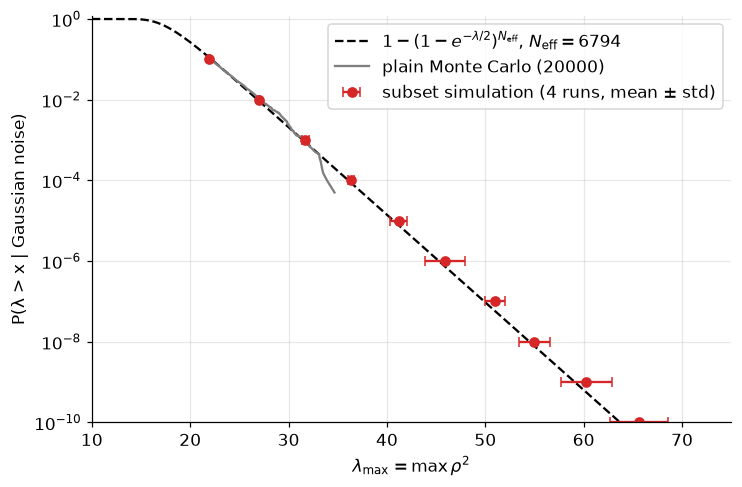

,FAP,threshold_SS,std_SS,threshold_formula,difference
0,0.10,21.92,0.09,22.15,-0.23
1,0.01,26.98,0.07,26.85,0.13
2,0.00,31.72,0.37,31.46,0.26
3,0.00,36.38,0.29,36.07,0.31
4,0.00,41.20,0.87,40.67,0.53
5,0.00,45.89,2.03,45.28,0.62
6,0.00,50.97,1.00,49.88,1.08
7,0.00,54.97,1.59,54.49,0.48
8,0.00,60.29,2.63,59.09,1.19
9,0.00,65.64,2.96,63.69,1.95


In [3]:
cum = np.cumprod(RUNS[0][1]); levels_p = cum
est = np.array([np.cumprod(pr) for _, pr in RUNS]); thr_all = np.array([t for t, _ in RUNS])
L = min(est.shape[1], thr_all.shape[1]); mean_thr = np.mean(thr_all[:, :L], 0); sd_thr = np.std(thr_all[:, :L], 0)         # threshold at fixed FAP 10^-k, scatter across repetitions
pk = np.cumprod([0.1] * L)
analytic = lambda x: 1 - (1 - np.exp(-x / 2)) ** N_EFF
x_an = np.linspace(10, 80, 400)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.semilogy(x_an, analytic(x_an), "k--", label=r"$1-(1-e^{-\lambda/2})^{N_{\rm eff}}$, $N_{\rm eff}=%.0f$" % N_EFF)
xs = np.sort(direct); ax.semilogy(xs[::-1][:2000], (np.arange(2000) + 1) / len(xs), color=g.COLORS["grey"], label="plain Monte Carlo (20000)")
ax.errorbar(mean_thr, pk, xerr=sd_thr, fmt="o", color=g.COLORS["bayes"], capsize=3, label="subset simulation (4 runs, mean ± std)")
ax.set_xlabel(r"$\lambda_{\max}=\max\rho^2$"); ax.set_ylabel("P(λ > x | Gaussian noise)"); ax.set_ylim(1e-10, 1.2); ax.set_xlim(10, 75); ax.legend(); g.savefig(fig, "fig24_subset_simulation"); plt.show()
tab = pd.DataFrame(dict(FAP=pk, threshold_SS=mean_thr, std_SS=sd_thr, threshold_formula=[float(-2 * np.log(1 - (1 - f) ** (1 / N_EFF))) for f in pk]))
tab["difference"] = tab.threshold_SS - tab.threshold_formula; tab.round(2)

In [4]:
rt = {f: float(g.threshold_at_far(direct, f)) for f in (1e-2, 1e-3)}; print("plain MC thresholds:", rt, " subset simulation:", {f: round(float(m), 2) for f, m in zip(pk[:3], mean_thr[:3])})
g.save_json(dict(N_eff=float(N_EFF), table=tab.to_dict("records"), plain_mc=rt), "24_summary.json")

plain MC thresholds: {0.01: 27.19023344039917, 0.001: 31.598250427246125}  subset simulation: {np.float64(0.1): 21.92, np.float64(0.010000000000000002): 26.98, np.float64(0.0010000000000000002): 31.72}


## Output and next step

`results/24_summary.json`, `figures/fig24_subset_simulation`. Next: seed study of the networks (extension 2) and the robustness of the ML detectors (extensions 5, 6).